# IoT Sensor Data Processor — Week 1 Lab

**Goal:** Load a raw CSV → clean it with reusable functions → analyze using **NumPy** → export useful reports and visualize sensor readings.

- Dataset: **synthetic** temperature and humidity readings from three classroom-demo sensors.
- Expected: **38 raw rows → 30 clean rows**, 8 rejected rows.
- No trained ML model is used; alert thresholds are simple practice rules.

**Google Colab:** click **Runtime → Run all** and upload `raw_sensor_readings.csv` when requested (included in the ZIP).

## 1. Import libraries and configure sample thresholds

In [1]:
import csv
from collections import Counter
from datetime import datetime
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt

REQUIRED_COLUMNS = ("timestamp", "sensor_id", "temperature_c", "humidity_pct")
MIN_TEMP_C, MAX_TEMP_C = -20.0, 60.0
HOT_THRESHOLD_C, HIGH_HUMIDITY_PCT = 30.0, 70.0
print("Libraries imported! NumPy version:", np.__version__)

Libraries imported! NumPy version: 2.3.5


## 2. Load the raw CSV

A CSV holds a table of records. A `DictReader` reads each row as a dictionary: column names become keys. If you're running only this notebook on Colab, a file-upload box will appear automatically.

In [2]:
def load_csv(path):
    """Read rows from a CSV file into a list of dictionaries."""
    with open(path, newline="", encoding="utf-8-sig") as file:
        reader = csv.DictReader(file)
        if not reader.fieldnames or not set(REQUIRED_COLUMNS).issubset(reader.fieldnames):
            raise ValueError(f"CSV must contain these columns: {', '.join(REQUIRED_COLUMNS)}")
        return list(reader)

csv_path = Path("data/raw_sensor_readings.csv")
if not csv_path.is_file():
    csv_path = Path("raw_sensor_readings.csv")
if not csv_path.is_file():
    try:
        from google.colab import files
        print("Please upload raw_sensor_readings.csv from the project ZIP")
        uploaded = files.upload()
        if "raw_sensor_readings.csv" not in uploaded:
            raise FileNotFoundError("Please upload the exact file: raw_sensor_readings.csv")
        csv_path = Path("raw_sensor_readings.csv")
    except ImportError as exc:
        raise FileNotFoundError("Place the raw CSV in data/ or beside this notebook") from exc

raw_rows = load_csv(csv_path)
print("CSV file:", csv_path)
print("Raw data rows:", len(raw_rows))
print("Example first row:", raw_rows[0])

CSV file: data/raw_sensor_readings.csv
Raw data rows: 38
Example first row: {'timestamp': '2026-10-18T09:00:00', 'sensor_id': ' room_a ', 'temperature_c': '23.3', 'humidity_pct': '50'}


## 3. Clean the data with a Python function

For each row we:

1. Normalize sensor IDs (spaces removed, uppercase).
2. Check timestamp and numeric fields.
3. Drop invalid or out-of-range measurements (temperature −20 to 60 °C; humidity 0 to 100%).
4. Drop duplicate `(timestamp, sensor_id)` records, keeping the first valid entry.

The function returns both the cleaned rows and a count of rejection reasons.

In [3]:
def clean_data(raw_rows):
    """Normalize rows, remove duplicate readings, and reject invalid values."""
    cleaned = []
    rejected = Counter()
    seen_readings = set()

    for row in raw_rows:
        sensor_id = (row.get("sensor_id") or "").strip().upper()
        time_text = (row.get("timestamp") or "").strip()
        if not sensor_id or not time_text:
            rejected["missing sensor ID or timestamp"] += 1
            continue

        try:
            timestamp = datetime.fromisoformat(time_text).isoformat(timespec="seconds")
        except ValueError:
            rejected["invalid timestamp"] += 1
            continue

        try:
            temperature = float((row.get("temperature_c") or "").strip())
            humidity = float((row.get("humidity_pct") or "").strip())
        except (TypeError, ValueError):
            rejected["missing or nonnumeric measurement"] += 1
            continue

        if not np.isfinite(temperature) or not np.isfinite(humidity):
            rejected["non-finite measurement"] += 1
            continue
        if not (MIN_TEMP_C <= temperature <= MAX_TEMP_C and 0 <= humidity <= 100):
            rejected["out-of-range measurement"] += 1
            continue

        reading_key = (timestamp, sensor_id)
        if reading_key in seen_readings:
            rejected["duplicate sensor and timestamp"] += 1
            continue
        seen_readings.add(reading_key)

        cleaned.append({
            "timestamp": timestamp,
            "sensor_id": sensor_id,
            "temperature_c": temperature,
            "humidity_pct": humidity,
        })

    return sorted(cleaned, key=lambda r: (r["timestamp"], r["sensor_id"])), rejected

cleaned_rows, rejection_reasons = clean_data(raw_rows)
print(f"Raw={len(raw_rows)}, Clean={len(cleaned_rows)}, Rejected={sum(rejection_reasons.values())}")
for reason, count in sorted(rejection_reasons.items()):
    print(f"  {reason}: {count}")
print("Example cleaned row:", cleaned_rows[0])
assert len(raw_rows) == len(cleaned_rows) + sum(rejection_reasons.values())

Raw=38, Clean=30, Rejected=8
  duplicate sensor and timestamp: 1
  invalid timestamp: 1
  missing or nonnumeric measurement: 2
  missing sensor ID or timestamp: 1
  non-finite measurement: 1
  out-of-range measurement: 2
Example cleaned row: {'timestamp': '2026-10-18T09:00:00', 'sensor_id': 'ROOM_A', 'temperature_c': 23.3, 'humidity_pct': 50.0}


## 4. Analyze readings using NumPy

**Vectorization** means applying operations to whole arrays without writing a Python loop for each number. For example, `temperatures >= 30` produces a Boolean array. The `|` operator combines hot and humid conditions element by element.

We also use **Boolean masks** to select rows belonging to each sensor.

In [4]:
def analyze_data(cleaned):
    """Use NumPy for vectorized statistics and high-reading detection."""
    if not cleaned:
        raise ValueError("No valid readings remained after cleaning.")

    temperatures = np.array([r["temperature_c"] for r in cleaned], dtype=float)
    humidity = np.array([r["humidity_pct"] for r in cleaned], dtype=float)
    sensors = np.array([r["sensor_id"] for r in cleaned])
    alerts = (temperatures >= HOT_THRESHOLD_C) | (humidity >= HIGH_HUMIDITY_PCT)

    overall = {
        "valid_readings": len(cleaned),
        "average_temperature_c": float(np.mean(temperatures)),
        "min_temperature_c": float(np.min(temperatures)),
        "max_temperature_c": float(np.max(temperatures)),
        "average_humidity_pct": float(np.mean(humidity)),
        "alert_readings": int(np.sum(alerts)),
    }

    per_sensor = []
    for sensor_id in np.unique(sensors):
        mask = sensors == sensor_id  # Boolean indexing: select one sensor.
        per_sensor.append({
            "sensor_id": str(sensor_id),
            "readings": int(np.sum(mask)),
            "avg_temperature_c": round(float(np.mean(temperatures[mask])), 2),
            "avg_humidity_pct": round(float(np.mean(humidity[mask])), 2),
            "alert_readings": int(np.sum(alerts[mask])),
        })
    return overall, per_sensor

overall, per_sensor = analyze_data(cleaned_rows)
print("OVERALL NUMPY ANALYSIS")
for name, value in overall.items():
    print(f"  {name}: {value:.2f}" if isinstance(value, float) else f"  {name}: {value}")
print("\nPER SENSOR")
for row in per_sensor:
    print(row)

OVERALL NUMPY ANALYSIS
  valid_readings: 30
  average_temperature_c: 26.82
  min_temperature_c: 22.10
  max_temperature_c: 34.44
  average_humidity_pct: 61.23
  alert_readings: 14

PER SENSOR
{'sensor_id': 'ROOM_A', 'readings': 10, 'avg_temperature_c': 25.54, 'avg_humidity_pct': 50.9, 'alert_readings': 0}
{'sensor_id': 'ROOM_B', 'readings': 10, 'avg_temperature_c': 31.47, 'avg_humidity_pct': 61.3, 'alert_readings': 7}
{'sensor_id': 'ROOM_C', 'readings': 10, 'avg_temperature_c': 23.45, 'avg_humidity_pct': 71.5, 'alert_readings': 7}


## 5. Export cleaned CSV and per-sensor report

CSV output means the result can be reopened in Excel, Python, or another tool. Reports are saved in `outputs/`.

In [5]:
def write_csv(path, rows, columns):
    """Save a CSV report with a header, creating its folder if necessary."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    with open(path, "w", newline="", encoding="utf-8") as file:
        writer = csv.DictWriter(file, fieldnames=columns)
        writer.writeheader()
        writer.writerows(rows)

out_dir = Path("outputs")
write_csv(out_dir / "cleaned_sensor_readings.csv", cleaned_rows, REQUIRED_COLUMNS)
write_csv(out_dir / "sensor_summary.csv", per_sensor,
          ("sensor_id", "readings", "avg_temperature_c", "avg_humidity_pct", "alert_readings"))
print("Wrote:", out_dir / "cleaned_sensor_readings.csv")
print("Wrote:", out_dir / "sensor_summary.csv")

Wrote: outputs/cleaned_sensor_readings.csv
Wrote: outputs/sensor_summary.csv


## 6. Plot sensor temperatures

The dotted line marks the illustrative 30 °C alert threshold. A sensor below that line could still trigger an alert from high humidity.

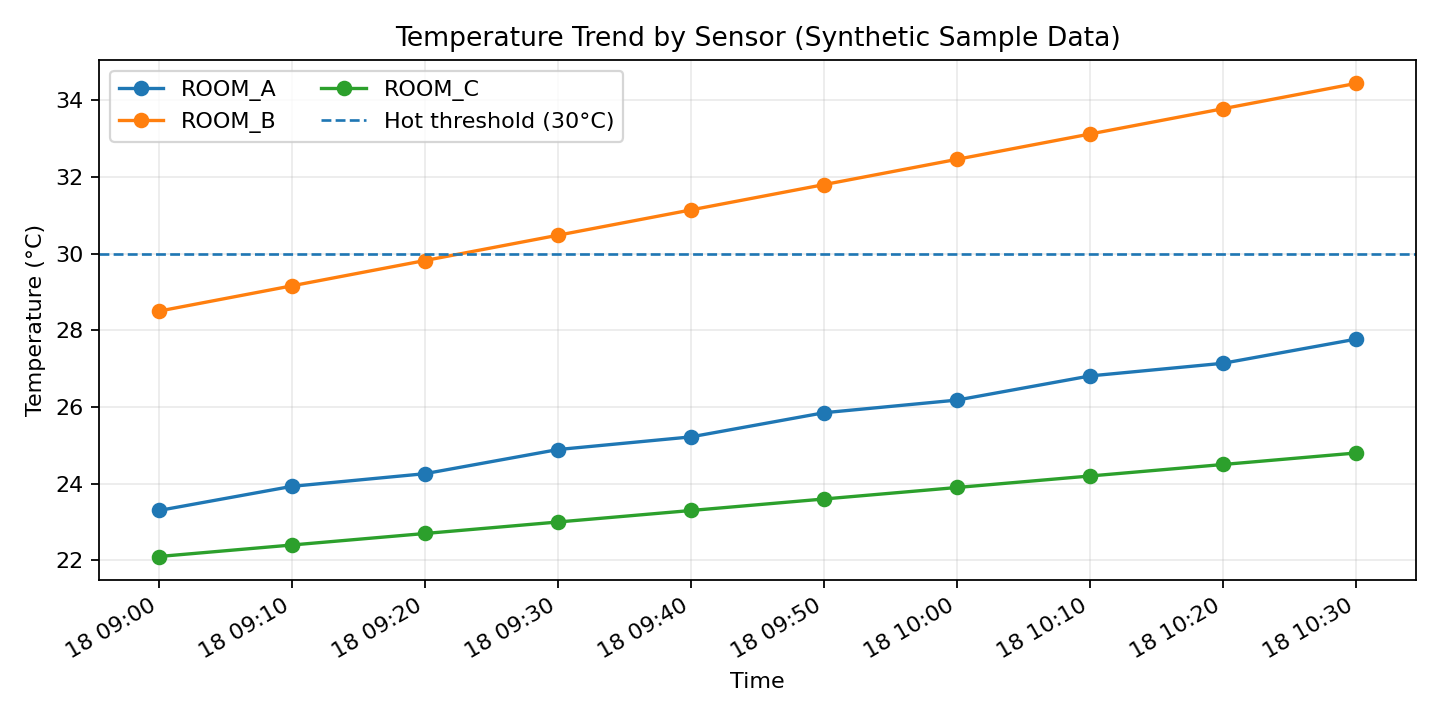

Chart saved: outputs/temperature_trend.png


In [6]:
def plot_temperatures(cleaned, path):
    """Save a temperature trend chart for each sensor."""
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    fig, ax = plt.subplots(figsize=(9, 4.5))
    for sensor_id in sorted({row["sensor_id"] for row in cleaned}):
        records = [r for r in cleaned if r["sensor_id"] == sensor_id]
        xs = [datetime.fromisoformat(r["timestamp"]) for r in records]
        ys = [r["temperature_c"] for r in records]
        ax.plot(xs, ys, marker="o", linewidth=1.5, label=sensor_id)
    ax.axhline(HOT_THRESHOLD_C, linestyle="--", linewidth=1.2, label="Hot threshold (30°C)")
    ax.set_title("Temperature Trend by Sensor (Synthetic Sample Data)")
    ax.set_ylabel("Temperature (°C)")
    ax.set_xlabel("Time")
    ax.legend(ncol=2)
    ax.grid(alpha=0.25)
    fig.autofmt_xdate()
    fig.tight_layout()
    fig.savefig(path, dpi=160)
    plt.close(fig)

chart_path = out_dir / "temperature_trend.png"
plot_temperatures(cleaned_rows, chart_path)
from IPython.display import display, Image
display(Image(filename=str(chart_path)))
print("Chart saved:", chart_path)

## 7. Verify and download results (Colab)

These checks confirm that our example dataset was processed as expected. In Colab the following cell displays links that let you download the reports. Locally, the same files remain inside the `outputs` folder.

In [7]:
assert len(raw_rows) == 38, "Unexpected input: this exercise expects the sample CSV"
assert len(cleaned_rows) == 30, "Expected 30 cleaned sample rows"
assert overall["alert_readings"] == 14, "Expected 14 flagged sample readings"
print("All sample checks passed! ✅")

try:
    from google.colab import files
    print("In Colab, you can also use the left Files panel to download outputs/ files.")
except ImportError:
    print("Your results are in the outputs/ folder.")

All sample checks passed! ✅
Your results are in the outputs/ folder.


## Key takeaways

- **Python functions** isolate cleaning and analysis logic so it can be reused.
- **NumPy arrays** simplify fast numerical statistics and Boolean filters.
- **CSV + `requirements.txt`** allow others to rerun the work.
- A **GitHub repo** should contain this notebook, `src/processor.py`, raw CSV, README, and dependency list.

**Try this:** change `HOT_THRESHOLD_C` from `30.0` to `32.0`, rerun the notebook, and explain why the number of flagged rows changes.